# 04 · Volatility, regimes and the FX overlay

Loads `data/processed/weekly.csv` and `daily_factor.csv`, saves `data/processed/overlay.csv`.

The direction of the factor proved unpredictable (notebook 03). This notebook uses the models
for what is predictable, next week's volatility, and builds the FX overlay for a Swiss investor
holding 100,000 CHF of S&P 500.

Steps (see PLAN.md, sections 5c and 5d):
1. Load the data and set aside the holdout (2024 onward is not used here)
2. PCA: is the basket really the main common force of the 14 pairs?
3. Inputs and target for the volatility models
4. Four volatility forecasts, walk-forward: naive, linear regression, GARCH, Gaussian process
5. Forecast accuracy: which model beats the naive forecast?
6. Market regimes: GMM, compared with k-means
7. The two FX overlays: trend rule and model
8. The four portfolios in CHF
9. Crisis table and performance table
10. Risk-targeting the equity allocation with the FX signal
11. Results of risk-targeting
12. Volatility-managed carry: the factor as a standalone strategy
13. Risk management: Value at Risk
14. Risk management: keeping risk on budget
15. Checks

In [ ]:
import numpy as np
import pandas as pd
from arch import arch_model
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.linear_model import LinearRegression
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy import stats

import helpers

np.random.seed(helpers.SEED)

## 1. Load the data and set aside the holdout

In [ ]:
weekly = pd.read_csv(f"{helpers.PROCESSED}/weekly.csv", index_col=0, parse_dates=True)
daily = pd.read_csv(f"{helpers.PROCESSED}/daily_factor.csv", index_col=0, parse_dates=True).iloc[:, 0]

# The holdout (2024 onward) stays untouched until the very end of the project
weekly = weekly[weekly.index.year <= helpers.LAST_TEST_YEAR]
daily = daily[daily.index.year <= helpers.LAST_TEST_YEAR]

factor = weekly["factor"]
rv = weekly["rv"]
print("Weeks:", len(weekly), "to", weekly.index[-1].date(), "| days:", len(daily))

Weeks: 1453 to 2026-11-13 | days: 7266


## 2. PCA: is the basket the main common force?

In [ ]:
# PCA finds, on its own, the combinations of pairs that explain most of the movement.
# If the first one looks like our equal-weight basket, the factor is confirmed.
pair_cols = [f"ret_{p}" for p in helpers.ALL_PAIRS]
pca = PCA().fit(weekly[pair_cols])

share = pca.explained_variance_ratio_
print(f"First component explains {share[0]:.0%} of all movement (second: {share[1]:.0%})")

# Its weights, sign-adjusted so the average weight is positive
w = pd.Series(pca.components_[0], index=helpers.ALL_PAIRS)
w = w * np.sign(w.mean())
print("\nWeights of the first component (the basket uses 1/14 = 0.07 everywhere):")
print(w.round(2).to_string())

same_sign = (w > 0).sum()
print(f"\n{same_sign} of 14 weights are positive")
pc1 = weekly[pair_cols].values @ (w / w.abs().sum()).values
corr = np.corrcoef(pc1, weekly["factor_spot"])[0, 1]
print(f"Correlation of the first component with the basket: {corr:.3f}")

pd.DataFrame({"pc1_weight": w, "variance_share": share[:len(w)]}).to_csv(f"{helpers.PROCESSED}/pca.csv")

First component explains 47% of all movement (second: 21%)

Weights of the first component (the basket uses 1/14 = 0.07 everywhere):
CADJPY    0.39
AUDUSD    0.28
USDJPY    0.22
EURUSD    0.14
EURCHF    0.05
GBPJPY    0.39
USDCAD   -0.18
GBPUSD    0.17
EURGBP   -0.04
GBPCHF    0.09
CHFJPY    0.31
AUDJPY    0.50
EURJPY    0.36
USDCHF   -0.09

11 of 14 weights are positive
Correlation of the first component with the basket: 0.958


## 3. Inputs and target for the volatility models

In [ ]:
# We work with the logarithm of volatility: it makes big and small weeks comparable.
# Inputs known at the Friday close of week t; target is next week's volatility.
log_rv = np.log(rv)
X = pd.DataFrame({
    "log_rv_1w": log_rv,
    "log_rv_4w": np.log(rv.rolling(4).mean()),
    "log_rv_13w": np.log(rv.rolling(13).mean()),
    "log_vix": np.log(weekly["VIX"]),
})
y = log_rv.shift(-1).rename("log_rv_next")

valid = X.dropna().index.intersection(y.dropna().index)
X, y = X.loc[valid], y.loc[valid]
print("Rows:", len(X), "from", X.index[0].date(), "to", X.index[-1].date())

Rows: 1440 from 1999-04-09 to 2026-11-06


## 4. Four volatility forecasts, walk-forward

In [ ]:
# For each test year (2010 to 2023), every model is estimated on the years before it.
# All four produce, at each Friday, a forecast of NEXT week's volatility (annualised).

test_years = range(helpers.FIRST_TEST_YEAR, helpers.LAST_TEST_YEAR + 1)
fc_naive, fc_reg, fc_garch, fc_gp, fc_gp_std, reg_adj = [], [], [], [], [], []
reg_coefs, gp_scales = {}, {}   # saved for the diagnostics in notebook 05

for year in test_years:
    # Purge the last training week: its target is the first test week
    train = X.index[X.index.year < year][:-1]
    test = X.index[X.index.year == year]

    # Naive: next week's volatility = this week's
    fc_naive.append(X.loc[test, "log_rv_1w"])

    # Linear regression on the four inputs
    reg = LinearRegression().fit(X.loc[train], y.loc[train])
    fc_reg.append(pd.Series(reg.predict(X.loc[test]), index=test))
    # The model forecasts the LOG of volatility; exp() of it gives the median, which is too
    # low on average. The standard correction ("smearing") multiplies by the average of
    # exp(training error).
    smear = np.mean(np.exp(y.loc[train] - reg.predict(X.loc[train])))
    reg_coefs[year] = dict(zip(["intercept"] + list(X.columns), [reg.intercept_] + list(reg.coef_)))
    reg_adj.append(pd.Series(np.log(smear), index=test))

    # GARCH(1,1) on the daily factor returns. Parameters are estimated on data before
    # the test year (last_obs); forecasts then use each day's actual conditional state.
    # Returns are scaled by 1000 so the optimiser works on numbers near 1.
    scale = 1000
    d = daily[daily.index.year <= year] * scale
    res = arch_model(d, vol="GARCH", p=1, q=1).fit(last_obs=f"{year}-01-01", disp="off")
    f = res.forecast(horizon=5, start=f"{year}-01-01", reindex=True)
    # Average forecast variance over the next 5 days, annualised, back to our units
    var_week = f.variance.mean(axis=1) / scale**2
    vol_ann = np.sqrt(var_week * 252)
    # The forecast made on the last trading day on or before each Friday
    g = np.log(vol_ann).reindex(test, method="ffill")
    fc_garch.append(g)

    # Gaussian process on the last 5 years of the training window (standardised inputs).
    # It returns a forecast AND how unsure it is (a standard deviation).
    recent = train[-260:]
    scaler = StandardScaler().fit(X.loc[recent])
    kernel = (ConstantKernel() * RBF(length_scale=[1.0] * X.shape[1], length_scale_bounds=(0.01, 1000.0))
              + WhiteKernel())
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=helpers.SEED)
    gp.fit(scaler.transform(X.loc[recent]), y.loc[recent])
    mean, std = gp.predict(scaler.transform(X.loc[test]), return_std=True)
    # Learned length scale per input: a large value means the GP found that input irrelevant
    gp_scales[year] = dict(zip(X.columns, gp.kernel_.k1.k2.length_scale))
    fc_gp.append(pd.Series(mean, index=test))
    fc_gp_std.append(pd.Series(std, index=test))
    print(year, "done")

forecasts = pd.DataFrame({
    "naive": pd.concat(fc_naive), "regression": pd.concat(fc_reg),
    "garch": pd.concat(fc_garch), "gp": pd.concat(fc_gp),
})
gp_std = pd.concat(fc_gp_std)
realised = y.loc[forecasts.index]

# Volatility LEVELS used for sizing, VaR and risk budgets, corrected for the log bias:
# regression with its smearing factor, GP with exp(mean + variance / 2). Naive and GARCH need
# no correction. Accuracy (MSE, R2) is still measured on the logs.
vol_level = pd.DataFrame({
    "naive": np.exp(forecasts["naive"]),
    "regression": np.exp(forecasts["regression"] + pd.concat(reg_adj)),
    "garch": np.exp(forecasts["garch"]),
    "gp": np.exp(forecasts["gp"] + gp_std ** 2 / 2),
})
print("\nForecasts:", forecasts.shape)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


2007 done
2008 done
2009 done
2010 done


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


2011 done
2012 done


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


2013 done
2014 done
2015 done
2016 done
2017 done
2018 done
2019 done
2020 done


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


2021 done
2022 done
2023 done


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


2024 done
2025 done
2026 done

Forecasts: (1036, 4)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


## 5. Forecast accuracy

            MSE of log vol  R2 vs naive
naive                0.436        0.000
regression           0.280        0.358
garch                0.339        0.222
gp                   0.330        0.243


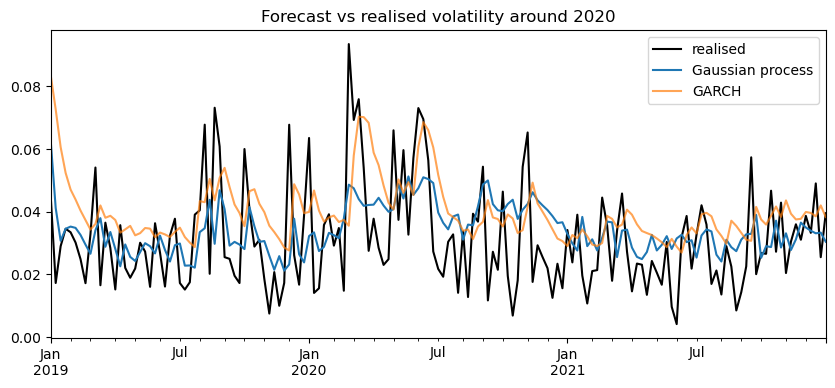

In [ ]:
# Mean squared error of log volatility, and the gain over the naive forecast
# (positive = better than naive; the same score the direction model failed on).
mse = ((forecasts.sub(realised, axis=0)) ** 2).mean()
r2_vs_naive = 1 - mse / mse["naive"]

summary = pd.DataFrame({"MSE of log vol": mse, "R2 vs naive": r2_vs_naive}).round(3)
print(summary.to_string())
summary.to_csv(f"{helpers.PROCESSED}/vol_accuracy.csv")
pd.DataFrame(reg_coefs).T.to_csv(f"{helpers.PROCESSED}/regression_coefs.csv")
pd.DataFrame(gp_scales).T.to_csv(f"{helpers.PROCESSED}/gp_length_scales.csv")
forecasts.join(gp_std.rename("gp_std")).join(realised.rename("realised")).join(
    vol_level.add_suffix("_level")).to_csv(
    f"{helpers.PROCESSED}/forecasts.csv")

ax = np.exp(realised)["2019":"2021"].plot(figsize=(10, 4), label="realised", color="black")
np.exp(forecasts["gp"])["2019":"2021"].plot(ax=ax, label="Gaussian process")
np.exp(forecasts["garch"])["2019":"2021"].plot(ax=ax, label="GARCH", alpha=0.7)
ax.legend(); ax.set_title("Forecast vs realised volatility around 2020");

## 6. Market regimes: GMM, compared with k-means

In [ ]:
# Each week is described by two numbers: how wild the factor is (log rv) and how scared
# the market is (log VIX). The carry is deliberately left out: it describes the return on
# offer, not the risk state, and including it makes the groups split on the post-2020
# interest rate era instead of on risk. GMM groups the weeks walk-forward: each year is
# labelled by a model fitted only on earlier years. The number of groups (2 or 3) is chosen
# by BIC, a score that rewards fit but punishes complexity.
Z = pd.DataFrame({"log_rv": np.log(rv), "log_vix": np.log(weekly["VIX"])}).dropna()

stress_gmm, stress_km, chosen_k = [], [], []
for year in test_years:
    train, test = Z.index[Z.index.year < year], Z.index[Z.index.year == year]
    sc = StandardScaler().fit(Z.loc[train])
    Ztr, Zte = sc.transform(Z.loc[train]), sc.transform(Z.loc[test])

    gmms = {k: GaussianMixture(k, random_state=helpers.SEED).fit(Ztr) for k in (2, 3)}
    k = min(gmms, key=lambda k: gmms[k].bic(Ztr))
    chosen_k.append(k)
    gmm = gmms[k]
    # The stress regime is the group with the highest average volatility in training
    vol_by_group = pd.Series(np.log(rv).loc[train].values).groupby(gmm.predict(Ztr)).mean()
    stress_gmm.append(pd.Series(gmm.predict(Zte) == vol_by_group.idxmax(), index=test))

    km = KMeans(2, n_init=10, random_state=helpers.SEED).fit(Ztr)
    vol_by_cluster = pd.Series(np.log(rv).loc[train].values).groupby(km.predict(Ztr)).mean()
    stress_km.append(pd.Series(km.predict(Zte) == vol_by_cluster.idxmax(), index=test))

stress = pd.concat(stress_gmm).rename("stress")
stress_k = pd.concat(stress_km)
pd.DataFrame({"stress_gmm": stress, "stress_kmeans": stress_k}).to_csv(f"{helpers.PROCESSED}/regimes.csv")
print("Groups chosen by BIC each year:", chosen_k)
print(f"Share of stress weeks (GMM): {stress.mean():.0%}")
print(f"GMM and k-means give the same label in {(stress == stress_k).mean():.0%} of weeks")
print("\nStress weeks per year:")
print(stress.groupby(stress.index.year).sum().to_string())

Groups chosen by BIC each year: [2, 2, 3, 3, 3, 3, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 3, 2]
Share of stress weeks (GMM): 23%
GMM and k-means give the same label in 71% of weeks

Stress weeks per year:
2007    25
2008    48
2009    15
2010     6
2011     8
2012     0
2013    17
2014     0
2015     0
2016     4
2017     1
2018     4
2019     0
2020     7
2021    25
2022    17
2023    17
2024     9
2025    25
2026    15


## 7. The two FX overlays

In [ ]:
# Both overlays run on top of the portfolio, sized by a 2% a year risk budget.
# Signals are known at the Friday close of week t and earn week t+1 (shift by one).

trend_52w = (1 + factor).rolling(52).apply(np.prod, raw=True) - 1
trend_sign = np.sign(trend_52w)

# Overlay 1, the trend rule: direction from the 52-week trend, fixed exposure set so the
# factor carries 2% risk, using only its volatility in the years before the test window.
size = helpers.overlay_size(factor)
print(f"Fixed overlay exposure: {size:.2f} of the portfolio")
pos_trend = (trend_sign * size).loc[forecasts.index]

# Overlay 2, the model: in calm weeks hold the carry (long); in stress weeks follow the trend.
# The size uses the Gaussian process forecast PLUS one standard deviation (its cautious
# estimate), so the position shrinks when volatility is high OR the model is unsure.
vol_cautious = np.exp(forecasts["gp"] + gp_std)
direction = pd.Series(1.0, index=forecasts.index).where(~stress, trend_sign.loc[forecasts.index])
pos_model = direction * (0.02 / vol_cautious).clip(upper=2.0)

# Weekly overlay returns, after costs (3 bp per unit of position change)
overlay = pd.DataFrame(index=forecasts.index)
for name, pos in [("trend", pos_trend), ("model", pos_model)]:
    held = pos.shift(1)
    cost = helpers.COST_BP / 1e4 * pos.diff().abs().fillna(0)
    overlay[name] = (held * factor.loc[held.index] - cost).fillna(0)

print("Average exposure: trend", f"{pos_trend.abs().mean():.2f},",
      "model", f"{pos_model.abs().mean():.2f}, cap 2.0")
print("Weeks short: trend", f"{(pos_trend < 0).mean():.0%},",
      "model", f"{(pos_model < 0).mean():.0%}")

Fixed overlay exposure: 0.45 of the portfolio
Average exposure: trend 0.45, model 0.34, cap 2.0
Weeks short: trend 38%, model 6%


## 8. The four portfolios in CHF

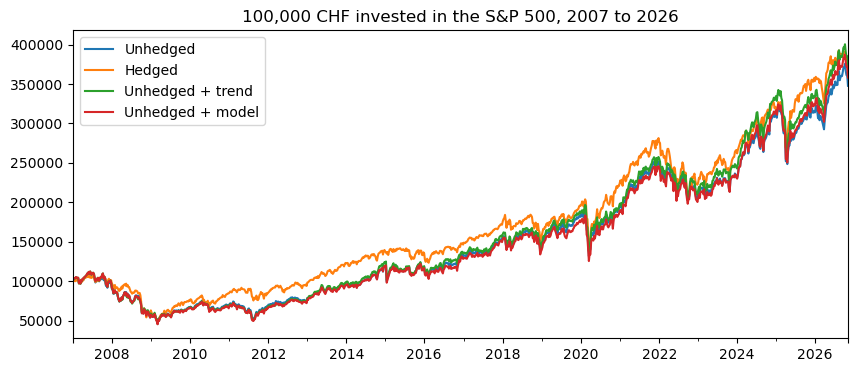

In [ ]:
# A Swiss investor with 100,000 CHF in the S&P 500, over the test years.
# His CHF return combines the index move and the dollar's move against the franc.
idx = overlay.index
sp_usd = weekly["sp500_ret"].loc[idx]
usd_chf = weekly["ret_USDCHF"].loc[idx]          # +1% = the dollar gains 1% vs the franc

portfolios = pd.DataFrame({
    "Unhedged": (1 + sp_usd) * (1 + usd_chf) - 1,
    # Hedging the dollar costs (roughly) the rate difference between CHF and USD
    "Hedged": sp_usd + (weekly["CHF_3M"] - weekly["USD_3M"]).loc[idx] / 100 / 52,
    "Unhedged + trend": (1 + sp_usd) * (1 + usd_chf) - 1 + overlay["trend"],
    "Unhedged + model": (1 + sp_usd) * (1 + usd_chf) - 1 + overlay["model"],
})

(1 + portfolios).cumprod().mul(100_000).plot(figsize=(10, 4),
    title=f"100,000 CHF invested in the S&P 500, {helpers.FIRST_TEST_YEAR} to {helpers.LAST_TEST_YEAR}");

## 9. Crisis table and performance table

In [ ]:
# What each portfolio lost, in CHF, in the crises inside the test window.
crises = {
    "2008 financial crisis": ("2008-09-01", "2009-03-09"),
    "2011 summer (euro crisis)": ("2011-07-01", "2011-09-30"),
    "2015 SNB shock (January)": ("2015-01-01", "2015-01-31"),
    "2018 Q4 selloff": ("2018-10-01", "2018-12-31"),
    "2020 Covid crash (Feb-Mar)": ("2020-02-15", "2020-03-31"),
    "2022 full year": ("2022-01-01", "2022-12-31"),
    "2024 August yen carry unwind": ("2024-07-15", "2024-08-16"),
    "2025 April tariff shock": ("2025-03-24", "2025-04-18"),
}
# Keep only the crises inside the test years
crises = {k: v for k, v in crises.items() if int(v[1][:4]) <= helpers.LAST_TEST_YEAR}
rows = {}
for name, (a, b) in crises.items():
    rows[name] = ((1 + portfolios.loc[a:b]).prod() - 1) * 100_000
crisis_table = pd.DataFrame(rows).T.round(0)
print("Change of a 100,000 CHF portfolio, in CHF:")
print(crisis_table.to_string())

# The worst 16% of quarters for the unhedged investor
quarterly = (1 + portfolios).resample("QE").prod() - 1
worst = quarterly["Unhedged"] <= quarterly["Unhedged"].quantile(0.16)
print(f"\nAverage quarter, in the worst {worst.sum()} quarters of the unhedged portfolio (CHF):")
print((quarterly[worst].mean() * 100_000).round(0).to_string())

# Performance over the whole test window
rf = weekly["CHF_3M"].loc[idx] / 100 / 52    # CHF risk-free rate, weekly
perf = pd.DataFrame({
    "return p.a.": (1 + portfolios).prod() ** (52 / len(portfolios)) - 1,
    "volatility": portfolios.std() * np.sqrt(52),
    "Sharpe (excess of CHF rate)": portfolios.apply(helpers.sharpe_ratio, risk_free=rf),
    "worst loss": portfolios.apply(helpers.max_drawdown),
}).round(3)
print("\nTest years:")
print(perf.to_string())

pd.concat([overlay, stress, pos_trend.rename("pos_trend"), pos_model.rename("pos_model"),
           portfolios], axis=1).to_csv(f"{helpers.PROCESSED}/overlay.csv")
print("\nSaved overlay.csv")

Change of a 100,000 CHF portfolio, in CHF:
                              Unhedged   Hedged  Unhedged + trend  Unhedged + model
2008 financial crisis         -43666.0 -46983.0          -41027.0          -43027.0
2011 summer (euro crisis)      -4422.0 -10820.0           -3743.0           -5393.0
2015 SNB shock (January)      -10541.0  -4498.0          -12854.0          -12067.0
2018 Q4 selloff               -13830.0 -15355.0          -12988.0          -14433.0
2020 Covid crash (Feb-Mar)    -26135.0 -25034.0          -25287.0          -26269.0
2022 full year                -18636.0 -20991.0          -18518.0          -18462.0
2024 August yen carry unwind   -3687.0  -1454.0           -4949.0           -4889.0
2025 April tariff shock       -13942.0  -7079.0          -14679.0          -14236.0

Average quarter, in the worst 13 quarters of the unhedged portfolio (CHF):
Unhedged           -11960.0
Hedged             -10736.0
Unhedged + trend   -11455.0
Unhedged + model   -11933.0

Test years:


## 10. Risk-targeting the equity allocation

In [ ]:
# The 2% overlay is too small to protect 100,000 CHF of equities. Here the same information
# changes the equity weight itself (the rest is held in CHF cash). Rules fixed in PLAN.md 5e.

# FX warning: the regression forecast of next week's FX volatility is above the 80th
# percentile of realised FX volatility in the training years (walk-forward, no future data).
fx_warning = []
for year in test_years:
    threshold = rv[rv.index.year < year].quantile(0.80)
    in_year = forecasts.index[forecasts.index.year == year]
    fx_warning.append(vol_level.loc[in_year, "regression"] > threshold)
fx_warning = pd.concat(fx_warning).rename("fx_warning")

# Equity volatility target: 16% a year (the long-run S&P average), using the VIX as the
# market's own forecast of equity volatility. No leverage: weight capped at 1.
vix = weekly["VIX"].loc[idx]
w_vol = (0.16 / (vix / 100)).clip(upper=1.0)

weights = pd.DataFrame({
    "Buy and hold": 1.0,
    "FX warning only": np.where(fx_warning, 0.5, 1.0),
    "Equity vol target": w_vol,
    "Equity vol target + FX warning": np.where(fx_warning, 0.5 * w_vol, w_vol),
}, index=idx)

print(f"FX warning in {fx_warning.mean():.0%} of weeks")
print("Average equity weight:")
print(weights.mean().round(2).to_string())

FX warning in 13% of weeks
Average equity weight:
Buy and hold                      1.00
FX warning only                   0.93
Equity vol target                 0.84
Equity vol target + FX warning    0.81


## 11. Results of risk-targeting

Change of a 100,000 CHF portfolio, in CHF:
                              Buy and hold  FX warning only  Equity vol target  Equity vol target + FX warning
2008 financial crisis             -43666.0         -23563.0           -19258.0                         -9620.0
2011 summer (euro crisis)          -4422.0          -8982.0            -6985.0                         -8850.0
2015 SNB shock (January)          -10541.0         -12190.0            -9956.0                        -11234.0
2018 Q4 selloff                   -13830.0         -13830.0           -13457.0                        -13457.0
2020 Covid crash (Feb-Mar)        -26135.0         -24245.0           -17455.0                        -16889.0
2022 full year                    -18636.0         -23813.0           -16490.0                        -19332.0
2024 August yen carry unwind       -3687.0          -3687.0            -4272.0                         -4272.0
2025 April tariff shock           -13942.0         -12950.0          

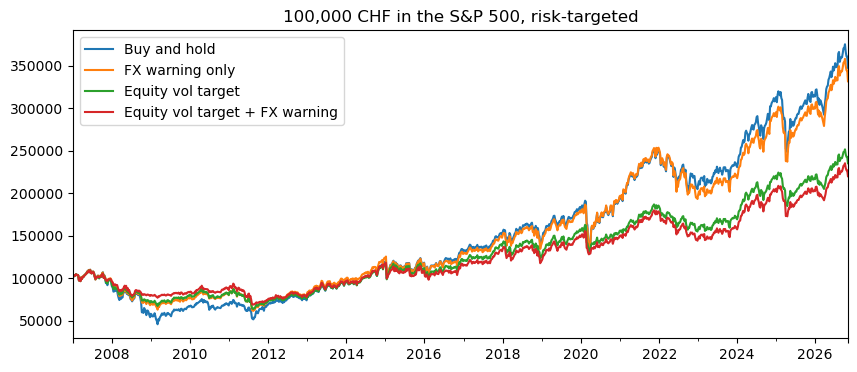

In [ ]:
# Weekly return: equity weight decided last Friday x S&P in CHF, plus cash at the CHF rate,
# minus 5 bp per unit of weight changed.
sp_chf = (1 + sp_usd) * (1 + usd_chf) - 1
cash = (weekly["CHF_3M"].loc[idx] / 100 / 52)

risk_targeted = pd.DataFrame(index=idx)
for name in weights.columns:
    w = weights[name].shift(1).fillna(1.0)
    cost = 5 / 1e4 * weights[name].diff().abs().fillna(0)
    risk_targeted[name] = w * sp_chf + (1 - w) * cash - cost

rows = {}
for name, (a, b) in crises.items():
    rows[name] = ((1 + risk_targeted.loc[a:b]).prod() - 1) * 100_000
print("Change of a 100,000 CHF portfolio, in CHF:")
print(pd.DataFrame(rows).T.round(0).to_string())

quarterly_rt = (1 + risk_targeted).resample("QE").prod() - 1
print(f"\nAverage quarter, in the worst {worst.sum()} quarters of the buy-and-hold portfolio (CHF):")
print((quarterly_rt[worst].mean() * 100_000).round(0).to_string())

perf_rt = pd.DataFrame({
    "return p.a.": (1 + risk_targeted).prod() ** (52 / len(risk_targeted)) - 1,
    "volatility": risk_targeted.std() * np.sqrt(52),
    "Sharpe (excess of CHF rate)": risk_targeted.apply(helpers.sharpe_ratio, risk_free=rf),
    "worst loss": risk_targeted.apply(helpers.max_drawdown),
}).round(3)
print("\nTest years:")
print(perf_rt.to_string())

risk_targeted.add_prefix("rt_").join(fx_warning).join(weights.add_prefix("w_")).to_csv(
    f"{helpers.PROCESSED}/risk_targeted.csv")
(1 + risk_targeted).cumprod().mul(100_000).plot(figsize=(10, 4),
    title="100,000 CHF in the S&P 500, risk-targeted");

## 12. Volatility-managed carry

Average position 1.25, at the cap 4% of weeks

Test years:
                   return p.a.  volatility  Sharpe  worst loss
Plain carry              0.011       0.054   0.224      -0.185
Vol-managed carry        0.011       0.058   0.212      -0.192


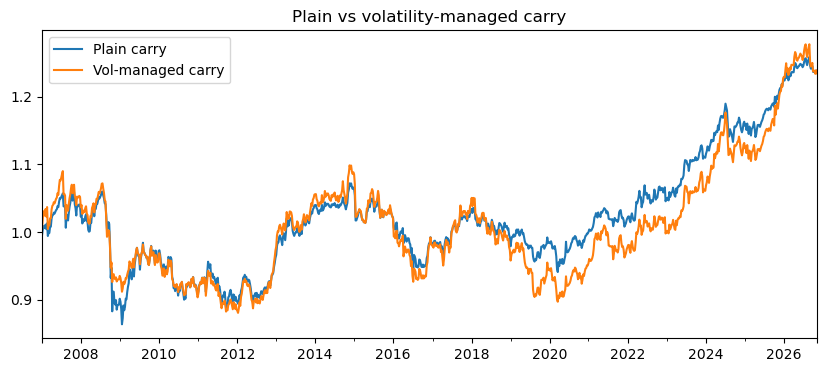

In [ ]:
# The factor as a standalone strategy (PLAN.md 5f). Plain carry holds it always.
# The managed version bets more when the regression forecasts a calm week and less when it
# forecasts a wild one: position = 5% / forecast volatility, capped at 2, long only.
pos_carry = (0.05 / vol_level["regression"]).clip(upper=2.0)

carry = pd.DataFrame(index=idx)
carry["Plain carry"] = factor.loc[idx]
held = pos_carry.shift(1)
cost = helpers.COST_BP / 1e4 * pos_carry.diff().abs().fillna(0)
carry["Vol-managed carry"] = (held * factor.loc[idx] - cost).fillna(0)

perf_carry = pd.DataFrame({
    "return p.a.": (1 + carry).prod() ** (52 / len(carry)) - 1,
    "volatility": carry.std() * np.sqrt(52),
    "Sharpe": carry.apply(helpers.sharpe_ratio),
    "worst loss": carry.apply(helpers.max_drawdown),
}).round(3)
print(f"Average position {pos_carry.mean():.2f}, at the cap {(pos_carry >= 2).mean():.0%} of weeks")
print("\nTest years:")
print(perf_carry.to_string())

carry.join(pos_carry.rename("pos_carry")).to_csv(f"{helpers.PROCESSED}/carry.csv")
(1 + carry).cumprod().plot(figsize=(10, 4), title="Plain vs volatility-managed carry");

## 13. Risk management: Value at Risk

In [ ]:
# Value at Risk (VaR): 'with 95% (or 99%) confidence, next week's loss on one unit of the
# factor will not exceed this'. VaR = z x forecast weekly volatility (normal, mean zero).
# Five ways to forecast the volatility; a good VaR is breached about 5% (1%) of the weeks,
# and the breaches do not come in clusters.
fixed = pd.concat([pd.Series(np.log(rv[rv.index.year < y].mean()), index=forecasts.index[forecasts.index.year == y])
                   for y in test_years])
vol_fc = pd.concat([np.exp(fixed).rename("fixed"), vol_level], axis=1)
weekly_sigma = vol_fc / np.sqrt(52)
next_ret = factor.shift(-1).loc[forecasts.index]
ok = next_ret.notna()

def kupiec(breaches, p):
    # Is the share of breaches equal to p? Likelihood ratio test, 1 degree of freedom
    n, x = len(breaches), int(breaches.sum())
    pi = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - pi) + (x * np.log(pi) if x > 0 else 0)
    return stats.chi2.sf(-2 * (ll0 - ll1), 1)

def christoffersen(breaches):
    # Are breaches independent (no clustering)? Compares the chance of a breach after a
    # breach with the chance after a normal week. 1 degree of freedom
    b = breaches.astype(int).values
    prev, cur = b[:-1], b[1:]
    n00, n01 = ((prev == 0) & (cur == 0)).sum(), ((prev == 0) & (cur == 1)).sum()
    n10, n11 = ((prev == 1) & (cur == 0)).sum(), ((prev == 1) & (cur == 1)).sum()
    def ll(k0, k1, q):   # log-likelihood of k0 non-breaches and k1 breaches with chance q
        return (k0 * np.log(1 - q) if k0 else 0) + (k1 * np.log(q) if k1 else 0)
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1)
    p = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)
    if p in (0, 1):
        return np.nan
    lr = -2 * (ll(n00 + n10, n01 + n11, p) - ll(n00, n01, p01) - ll(n10, n11, p11))
    return stats.chi2.sf(lr, 1)

rows = []
for level in (0.95, 0.99):
    z = stats.norm.ppf(level)
    for m in vol_fc.columns:
        breaches = (next_ret[ok] < -z * weekly_sigma.loc[ok, m])
        rows.append({"level": f"{level:.0%}", "model": m, "breach rate": breaches.mean(),
                     "expected": 1 - level, "Kupiec p": kupiec(breaches, 1 - level),
                     "Christoffersen p": christoffersen(breaches)})
var_table = pd.DataFrame(rows).set_index(["level", "model"]).round(3)
print(var_table.to_string())

var_table.to_csv(f"{helpers.PROCESSED}/var_backtest.csv")
pd.concat([next_ret.rename("next_ret"), weekly_sigma.add_prefix("sigma_")], axis=1).to_csv(
    f"{helpers.PROCESSED}/var_series.csv")

                  breach rate  expected  Kupiec p  Christoffersen p
level model                                                        
95%   fixed             0.061      0.05     0.122             0.272
      naive             0.104      0.05     0.000             0.668
      regression        0.061      0.05     0.122             0.543
      garch             0.046      0.05     0.584             0.089
      gp                0.057      0.05     0.315             0.374
99%   fixed             0.030      0.01     0.000             0.074
      naive             0.054      0.01     0.000             0.572
      regression        0.026      0.01     0.000             0.033
      garch             0.022      0.01     0.001             0.534
      gp                0.032      0.01     0.000             0.104


## 14. Risk management: keeping risk on budget

In [ ]:
# A risk manager wants the FX exposure to carry about 2% risk a year, whatever the market
# does. Exposure = 2% / forecast volatility (capped at 3). Judged on the risk actually taken:
# realised volatility in each quarter should stay close to 2%.
budget_returns = pd.DataFrame(index=forecasts.index)
for m in ["fixed", "naive", "regression", "gp"]:
    pos = (0.02 / vol_fc[m]).clip(upper=3.0)
    cost = helpers.COST_BP / 1e4 * pos.diff().abs().fillna(0)
    budget_returns[m] = (pos.shift(1) * factor.loc[forecasts.index] - cost).fillna(0)

quarterly_risk = budget_returns.resample("QE").std() * np.sqrt(52)
budget_table = pd.DataFrame({
    "average risk": quarterly_risk.mean(),
    "std of quarterly risk": quarterly_risk.std(),
    "share of quarters 1%-3%": ((quarterly_risk >= 0.01) & (quarterly_risk <= 0.03)).mean(),
    "highest quarter": quarterly_risk.max(),
}).round(4)
print(budget_table.to_string())

budget_table.to_csv(f"{helpers.PROCESSED}/risk_budget.csv")
quarterly_risk.to_csv(f"{helpers.PROCESSED}/risk_budget_quarterly.csv")

            average risk  std of quarterly risk  share of quarters 1%-3%  highest quarter
fixed             0.0216                 0.0126                   0.8125           0.1023
naive             0.0302                 0.0103                   0.5875           0.0639
regression        0.0222                 0.0063                   0.8625           0.0433
gp                0.0221                 0.0077                   0.8500           0.0527


## 15. Checks

In [ ]:
# No holdout data anywhere
for obj in (forecasts, stress, overlay, portfolios):
    assert obj.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout data used"

# Forecasts exist for every test week and are positive volatilities
assert forecasts.notna().all().all(), "Missing forecasts"
assert (np.exp(forecasts) > 0).all().all()

# Positions respect the cap
assert pos_model.abs().max() <= 2.0 + 1e-9, "Position cap exceeded"

# The stress regime exists and is a minority of weeks
assert 0 < stress.mean() < 0.5, "Stress regime share looks wrong"

# Signals are lagged: the overlay return of week t uses the position decided at t-1
assert overlay.index.equals(forecasts.index)

# Risk-targeting: no leverage, no holdout
assert weights.max().max() <= 1.0 and weights.min().min() >= 0, "Equity weight out of [0, 1]"
assert risk_targeted.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout data used"

# Risk management results exist for every model
assert var_table.notna()["breach rate"].all() and len(budget_table) == 4

# Volatility-managed carry: long only, capped
assert pos_carry.min() > 0 and pos_carry.max() <= 2.0 + 1e-9, "Carry position out of range"

print("All checks passed")

All checks passed
